<a href="https://colab.research.google.com/github/pendulumswings/pendulumswings.github.io/blob/main/scripts/chapter3/pendulum_bug_small_frequency.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Pendulum frequency as the Bug Crawls Outward (slow bug, small angle approximation).

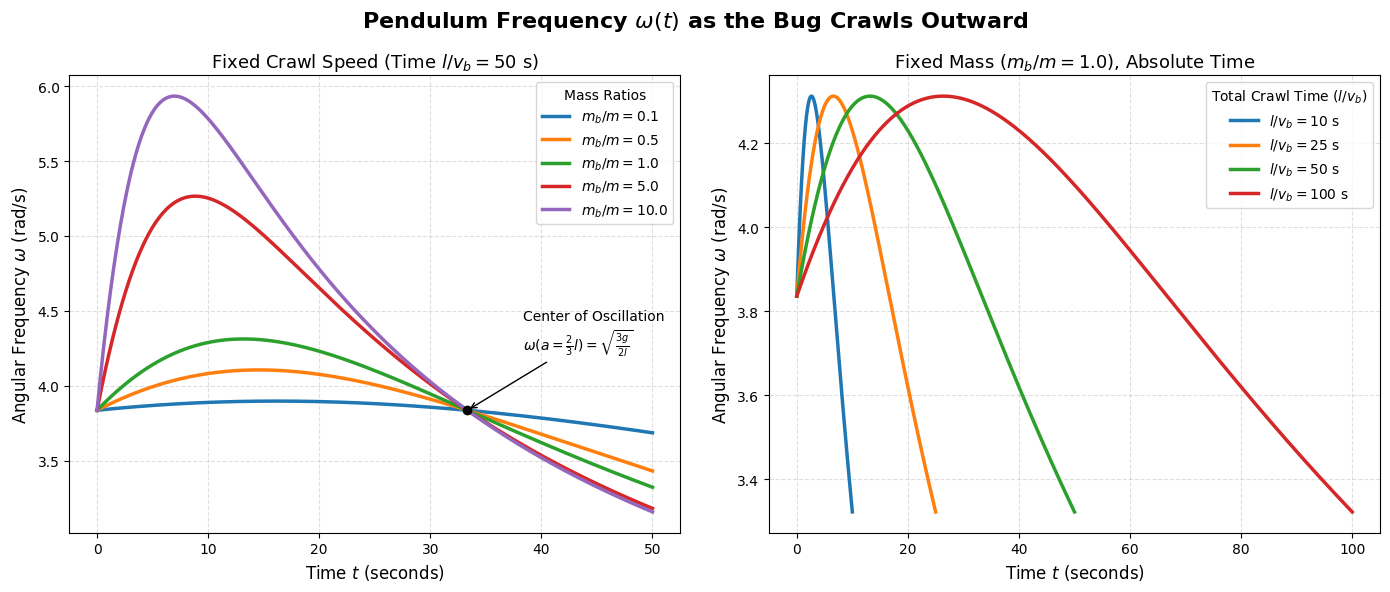

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def calc_omega(t, m, m_b, l, v_b, g=9.81):
    """
    Calculates the angular frequency of the pendulum as a function of time.
    Based on the formula: omega = sqrt( kappa(a) / I(a) )
    where a = v_b * t
    """
    a = v_b * t

    # Cap the bug's position at the end of the rod (a <= l)
    a = np.minimum(a, l)

    # Calculate effective restoring torque constant and moment of inertia
    kappa_a = g * (m * l / 2.0 + m_b * a)
    inertia_a = (1.0 / 3.0) * m * l**2 + m_b * a**2

    return np.sqrt(kappa_a / inertia_a)

if __name__ == "__main__":
    # Base dimensional parameters for scaling
    l = 1.0  # length of rod in meters
    m = 1.0  # mass of rod in kg
    g = 9.81 # gravity

    # Set up the figure dimensions
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
    fig.suptitle('Pendulum Frequency $\\omega(t)$ as the Bug Crawls Outward', fontsize=16, weight='bold')

    # ==========================================
    # Plot 1: Varying Mass Ratio (m_b / m)
    # ==========================================
    # Fix the crawl time (l/v_b) to 50 seconds
    fixed_crawl_time = 50.0
    v_b_fixed = l / fixed_crawl_time
    t1 = np.linspace(0, fixed_crawl_time, 500)

    # Mass ratios to test: Light bug (0.1) up to Heavy bug (10.0)
    mass_ratios = [0.1, 0.5, 1.0, 5.0, 10.0]

    for mb_ratio in mass_ratios:
        m_b = mb_ratio * m
        w = calc_omega(t1, m, m_b, l, v_b_fixed, g)
        ax1.plot(t1, w, linewidth=2.5, label=f'$m_b/m = {mb_ratio}$')

    # Mark the center of oscillation intersection in Plot 1
    t_intersect = (2/3 * l) / v_b_fixed
    w_intersect = np.sqrt(3 * g / (2 * l))
    ax1.plot(t_intersect, w_intersect, 'ko', markersize=6, zorder=5)
    ax1.annotate('Center of Oscillation\n$\\omega(a=\\frac{2}{3}l) = \\sqrt{\\frac{3g}{2l}}$',
                 xy=(t_intersect, w_intersect), xytext=(t_intersect + 5, w_intersect + 0.4),
                 arrowprops=dict(facecolor='black', arrowstyle='->'), fontsize=10)

    ax1.set_title(f'Fixed Crawl Speed (Time $l/v_b = 50$ s)', fontsize=13)
    ax1.set_xlabel('Time $t$ (seconds)', fontsize=12)
    ax1.set_ylabel('Angular Frequency $\\omega$ (rad/s)', fontsize=12)
    ax1.grid(True, alpha=0.4, linestyle='--')
    ax1.legend(title='Mass Ratios', fontsize=10)

    # ==========================================
    # Plot 2: Varying Speed Ratio (l / v_b)
    # ==========================================
    # Fix mass ratio to equal masses (m_b / m = 1.0)
    m_b_fixed = 1.0 * m

    # Total crawl time ratios to test (l / v_b)
    time_ratios = [10, 25, 50, 100]

    for t_ratio in time_ratios:
        v_b = l / t_ratio
        t2 = np.linspace(0, t_ratio, 500)
        w = calc_omega(t2, m, m_b_fixed, l, v_b, g)

        # We plot against absolute time t to show how the frequency drops at different rates
        ax2.plot(t2, w, linewidth=2.5, label=f'$l/v_b = {t_ratio}$ s')

    ax2.set_title(f'Fixed Mass ($m_b/m = 1.0$), Absolute Time', fontsize=13)
    ax2.set_xlabel('Time $t$ (seconds)', fontsize=12)
    ax2.set_ylabel('Angular Frequency $\\omega$ (rad/s)', fontsize=12)
    ax2.grid(True, alpha=0.4, linestyle='--')
    ax2.legend(title='Total Crawl Time ($l/v_b$)', fontsize=10)

    plt.tight_layout()
    plt.show()